# 04 · Evaluation: score files and leave-one-scenario-out (T6)

Owner: Ayo (Y16, Y17 step 8, Y18-H, Y20-H). The one results machine for T5, T6, T8 and F4–F6 (TEAM_PLAN 2.5).

Order: make sure every final score file exists (running any missing `final` command, so nothing depends on received files) → `evaluate_file()` on each (M3 check) → LOSO on v1 with the tuned defaults and each model's set-up (`ms.FINAL_SETUP`) → `loso.csv` (T6) and the PR-AUC pivot.

Run with Restart & Run All. LOSO takes about 20 minutes (6 fits; Random Forest with SMOTE is the slow one). It reruns only if `loso.csv` is missing or `RERUN_LOSO = True`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import pandas as pd

from src import models_supervised as ms
from src import models_unsupervised as mu
from src.config import PROCESSED_DIR, SCORES_DIR, TABLES_DIR
from src.evaluate import evaluate_file

FEATURES = PROCESSED_DIR / "features_v1.parquet"
RERUN_LOSO = False
UNSUPERVISED = ["iforest", "autoencoder", "iforest_contam", "autoencoder_contam", "ocsvm"]
SUPERVISED = list(ms.MODELS)
df = pd.read_parquet(FEATURES)
print(f"{FEATURES.name}: {len(df):,} user-days, {df['label'].sum():,} malicious")

features_v1.parquet: 330,268 user-days, 984 malicious


## 1 · Final score files
Runs `python -m src.models_unsupervised final` / `python -m src.models_supervised final` only for a family with a missing file.

In [2]:
def missing(names):
    return [n for n in names if not (SCORES_DIR / f"{n}.parquet").exists()]

if missing(UNSUPERVISED):
    print("running the unsupervised final for", missing(UNSUPERVISED))
    mu.final(df=df)
if missing(SUPERVISED):
    print("running the supervised final for", missing(SUPERVISED))
    ms.final(df=df)
assert not missing(UNSUPERVISED + SUPERVISED)
print("all", len(UNSUPERVISED + SUPERVISED), "final score files present")

all 7 final score files present


## 2 · `evaluate_file()` on every score file (M3)
Test split only. Shown to check that each file evaluates; the comparison itself is Y17 (T5).

In [3]:
rows = []
for name in UNSUPERVISED + SUPERVISED:
    result = evaluate_file(SCORES_DIR / f"{name}.parquet")
    rows.append({"model": name, "test_pr_auc": result["ranking"]["pr_auc"],
                 "test_roc_auc": result["ranking"]["roc_auc"]})
pd.DataFrame(rows).round(4)

,model,test_pr_auc,test_roc_auc
0,iforest,0.0122,0.8792
1,autoencoder,0.0930,0.9160
2,iforest_contam,0.0101,0.8606
3,autoencoder_contam,0.0413,0.9018
4,ocsvm,0.0574,0.7412
5,random_forest,0.9658,0.9999
6,xgboost,0.9877,0.9997


## 3 · LOSO (T6)
Per held-out scenario: RF and XGBoost trained without that scenario's accounts (tuned defaults, `FINAL_SETUP`), and the Isolation Forest and autoencoder final score files evaluated on the same test rows. Writes `results/tables/loso.csv`, `loso_pr_auc.csv` and `results/scores/<model>_loso_s<1|2|3>.parquet`.

In [4]:
if RERUN_LOSO or not (TABLES_DIR / ms.LOSO_TABLE).exists():
    loso = ms.loso(df=df)
else:
    loso = pd.read_csv(TABLES_DIR / ms.LOSO_TABLE)
    print(f"read {ms.LOSO_TABLE}; set RERUN_LOSO = True to recompute")
for model in SUPERVISED:
    for s in (1, 2, 3):
        assert (SCORES_DIR / f"{model}_loso_s{s}.parquet").exists()
loso.round(4)

read loso.csv; set RERUN_LOSO = True to recompute


,held_out,model,kind,n_train,held_out_accounts,n_rows,n_malicious,pr_auc,roc_auc,recall_top1pct
0,1,random_forest,supervised (LOSO),203199.0,30.0,64846,9,0.1678,0.9925,0.7778
1,1,xgboost,supervised (LOSO),203199.0,30.0,64846,9,0.5011,0.9267,0.7778
2,1,iforest,unsupervised,NaN,NaN,64846,9,0.0043,0.9751,0.3333
3,1,autoencoder,unsupervised,NaN,NaN,64846,9,0.9234,1.0000,1.0000
4,2,random_forest,supervised (LOSO),203144.0,30.0,64994,157,0.0322,0.8154,0.2229
5,2,xgboost,supervised (LOSO),203144.0,30.0,64994,157,0.0030,0.5596,0.0000
6,2,iforest,unsupervised,NaN,NaN,64994,157,0.0101,0.8770,0.0318
7,2,autoencoder,unsupervised,NaN,NaN,64994,157,0.0240,0.9139,0.1274
8,3,random_forest,supervised (LOSO),206909.0,12.0,64841,4,0.2519,0.7191,0.5000
9,3,xgboost,supervised (LOSO),206909.0,12.0,64841,4,0.2507,0.6641,0.2500


In [5]:
pivot = ms.loso_pivot(loso)        # PR-AUC per held-out scenario, saved as loso_pr_auc.csv
pivot.round(4)

,kind,s1,s2,s3
model,,,,
random_forest,supervised (LOSO),0.1678,0.0322,0.2519
xgboost,supervised (LOSO),0.5011,0.0030,0.2507
iforest,unsupervised,0.0043,0.0101,0.0035
autoencoder,unsupervised,0.9234,0.0240,0.3383


In [6]:
# test rows per held-out scenario (the same for every model); scenario 3 has very few malicious days
loso.groupby("held_out")[["n_rows", "n_malicious"]].first()

,n_rows,n_malicious
held_out,,
1,64846,9
2,64994,157
3,64841,4


## 4 · Reading [H]

*Drafted by Claude at Ayo's request (Nov 9); numbers updated Nov 10 for the tuned Isolation Forest and autoencoder defaults (#50). Ayo to check it against the tables above. Full-training numbers: per-scenario test PR-AUC from `evaluate_file()` on `random_forest.parquet` / `xgboost.parquet`, the same test rows as LOSO.*

Yes, supervised PR-AUC drops sharply on the unseen scenario. With scenario 1 held out, Random Forest falls from 0.87 to 0.17 and XGBoost from 0.90 to 0.50. On scenario 2 both collapse: RF goes from 0.97 to 0.03, and XGBoost from 0.99 to 0.003, with ROC-AUC 0.56, close to chance. On scenario 3, XGBoost falls from 0.80 to 0.25 and RF from 0.32 to 0.25.

The unsupervised models never see labels, so their scores are identical with or without LOSO, but they are not uniformly good. The autoencoder keeps 0.92 on scenario 1 and 0.34 on scenario 3, ahead of both supervised models trained without those scenarios. Isolation Forest stays at about 0.01 or below everywhere.

No model detects an unseen scenario 2 well. The best is RF at 0.03, catching 22% of its 157 days in the top 1%.

These numbers rest on very few positives: 9 malicious test days for scenario 1 and only 4 for scenario 3 (one real insider with 2 days, plus 2 days on the hijacked `FBA0348` account). A single day moves PR-AUC a lot, so the scenario-3 results are indicative only and belong in Limitations.

## 5 · Model comparison for the walkthrough (Y17)
T5, the per-scenario recall and the detection delay, from `python -m src.evaluate report` (test split only). F4 is in `results/figures/F4_pr_curves.png`.

,model,operating_point,precision,recall,f1,fpr,pr_auc,roc_auc,user_recall
0,iforest,best_f1,0.0117,0.5235,0.0229,0.1159,0.0122,0.8792,0.9333
1,iforest,top_1pct,0.0138,0.0529,0.0219,0.0099,0.0122,0.8792,0.2667
2,autoencoder,best_f1,0.0720,0.1647,0.1002,0.0056,0.0930,0.9160,0.6667
3,autoencoder,top_1pct,0.0476,0.1824,0.0755,0.0096,0.0930,0.9160,0.7333
4,ocsvm,best_f1,0.8182,0.0529,0.0994,0.0000,0.0574,0.7412,0.4000
5,ocsvm,top_1pct,0.0384,0.1471,0.0609,0.0097,0.0574,0.7412,0.6667
6,iforest_contam,best_f1,0.0108,0.7118,0.0213,0.1712,0.0101,0.8606,1.0000
7,iforest_contam,top_1pct,0.0138,0.0529,0.0219,0.0099,0.0101,0.8606,0.2000
8,autoencoder_contam,best_f1,0.1020,0.0588,0.0746,0.0014,0.0413,0.9018,0.4667
9,autoencoder_contam,top_1pct,0.0338,0.1294,0.0536,0.0097,0.0413,0.9018,0.7333


scenario,1,2,3
model,,,
autoencoder,1.000,0.102,0.75
autoencoder_contam,0.889,0.000,0.50
iforest,1.000,0.497,0.50
iforest_contam,1.000,0.694,0.75
ocsvm,0.889,0.000,0.25
random_forest,1.000,0.879,0.50
xgboost,0.889,0.962,1.00


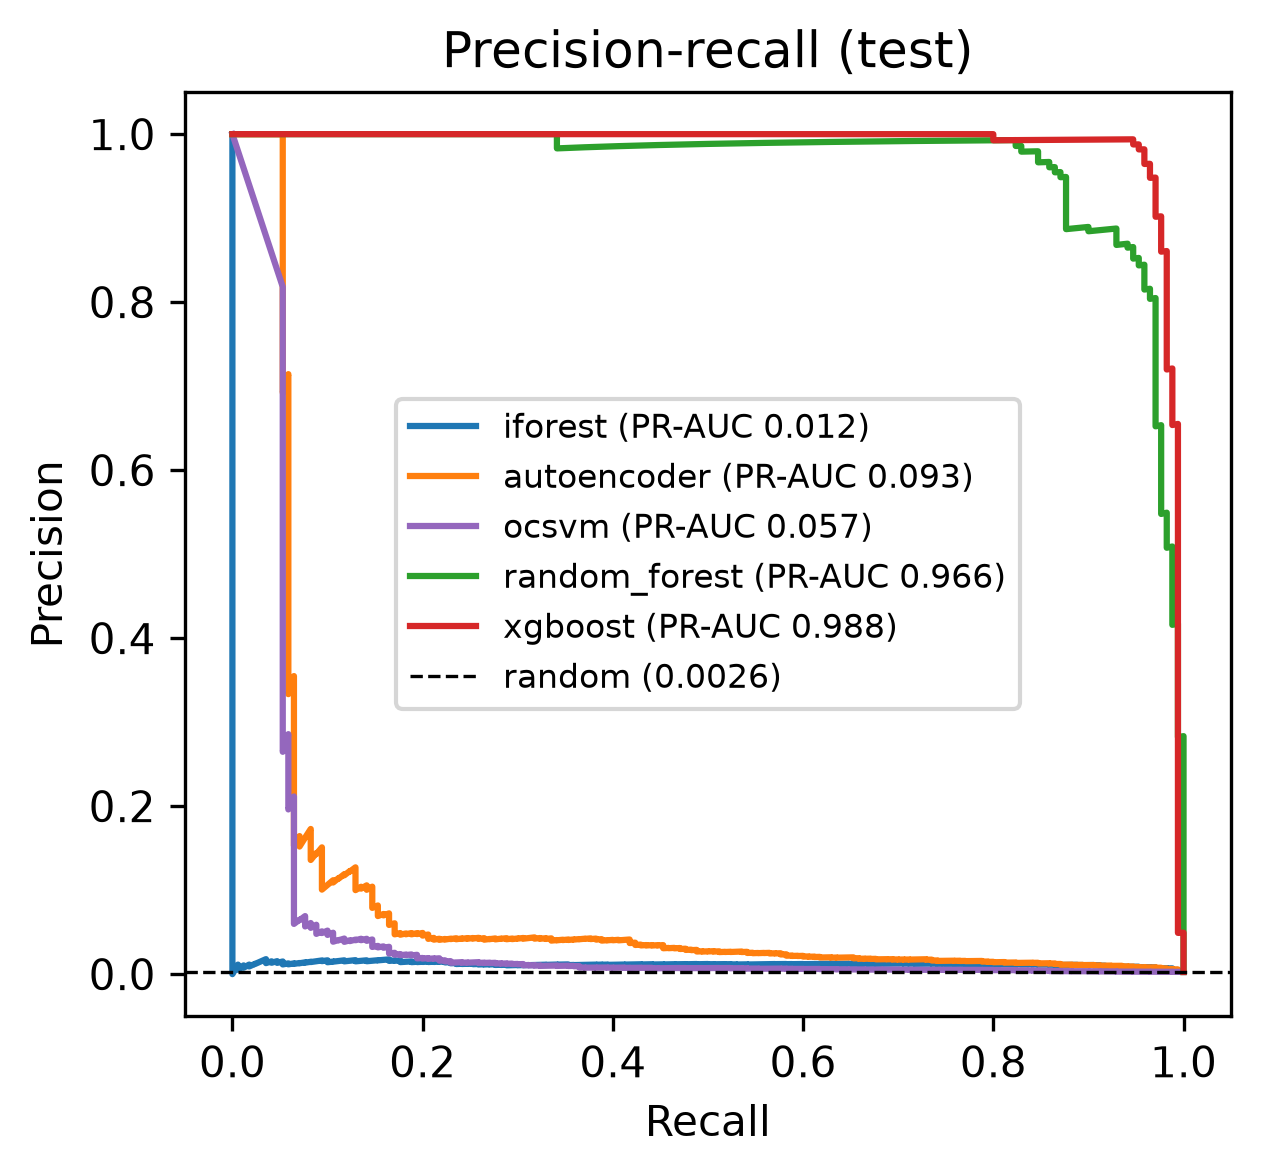

In [7]:
from IPython.display import Image, display

t5 = pd.read_csv(TABLES_DIR / "model_comparison.csv")
cols = ["model", "operating_point", "precision", "recall", "f1", "fpr", "pr_auc", "roc_auc", "user_recall"]
display(t5[cols].round(4))
per = pd.read_csv(TABLES_DIR / "model_per_scenario.csv")
display(per.pivot(index="model", columns="scenario", values="recall_best_f1").round(3))
display(Image(str(ROOT / "results" / "figures" / "F4_pr_curves.png"), width=600))

## 6 · SHAP and the feature-group ablation (Y18)
Share of each model's total mean |SHAP| per T7 feature group (`feature_importance.csv`), next to the T7 drop in test PR-AUC when the group is removed (`ablation.csv`, Supriye's S22). SHAP units differ by model, so compare shares within a model, not raw values.

In [8]:
imp = pd.read_csv(TABLES_DIR / "feature_importance.csv")
share = imp.groupby(["group", "model"])["mean_abs_shap"].sum().unstack()
share = (share / share.sum()).round(3)
if (TABLES_DIR / "ablation.csv").exists():
    ab = pd.read_csv(TABLES_DIR / "ablation.csv")
    drops = ab[ab["feature_set"].str.startswith("d_full_minus_")].assign(
        group=lambda d: d["feature_set"].str.replace("d_full_minus_", ""))
    drops = drops.pivot(index="group", columns="model", values="delta_pr_auc_vs_full").add_prefix("T7_drop_")
    share = share.join(drops)
else:
    print("ablation.csv is not on this branch yet (S22, #51); showing the SHAP shares only")
share.sort_values("xgboost", ascending=False)

ablation.csv is not on this branch yet (S22, #51); showing the SHAP shares only


model,iforest,random_forest,xgboost
group,,,
http,0.266,0.668,0.494
email,0.162,0.053,0.133
usb,0.115,0.221,0.131
logon,0.225,0.024,0.096
context,0.049,0.014,0.076
time,0.088,0.010,0.044
file,0.095,0.010,0.026


In [9]:
# share of mean |SHAP| by input type: own baseline (z_user_), peers (z_peer_), raw counts (f_), first-time flags (new_)
imp["kind"] = imp["feature"].str.extract(r"^(f_|z_user_|z_peer_|new_)")[0]
kind = imp.groupby(["kind", "model"])["mean_abs_shap"].sum().unstack()
display((kind / kind.sum()).round(3))
# per scenario: share of mean |SHAP| over that scenario's malicious test days, by group
ps = pd.read_csv(TABLES_DIR / "feature_importance_per_scenario.csv")
g = ps.groupby(["model", "scenario", "group"])["mean_abs_shap"].sum()
(g / g.groupby(level=[0, 1]).transform("sum")).unstack("group").round(2)

model,iforest,random_forest,xgboost
kind,,,
f_,0.615,0.352,0.473
new_,0.016,0.001,0.002
z_peer_,0.186,0.165,0.193
z_user_,0.183,0.482,0.333


group                   context  email  file  http  logon  time   usb
model         scenario                                               
iforest       1            0.02   0.11  0.02  0.18   0.36  0.16  0.15
              2            0.04   0.09  0.13  0.31   0.12  0.06  0.26
              3            0.03   0.07  0.04  0.19   0.37  0.21  0.08
random_forest 1            0.00   0.01  0.00  0.79   0.02  0.02  0.14
              2            0.02   0.01  0.01  0.75   0.01  0.00  0.19
              3            0.00   0.10  0.00  0.70   0.09  0.02  0.08
xgboost       1            0.04   0.10  0.01  0.60   0.13  0.06  0.07
              2            0.05   0.08  0.02  0.53   0.07  0.05  0.20
              3            0.06   0.17  0.02  0.48   0.13  0.06  0.09

### Reading (Y18-H) [H]

*Drafted by Claude at Ayo's request (Nov 12); Ayo to check it against the tables above before using it in the paper or the walkthrough.* *The T7 numbers are from #51 (fixed XGBoost tree count).*

**SHAP and the ablation agree on what matters most.** Web activity (HTTP) carries 49% of XGBoost's and 67% of Random Forest's mean |SHAP|, and removing the HTTP group is the only large T7 drop: XGBoost falls from 0.987 to 0.330 PR-AUC. USB is second for both supervised models in SHAP (13%, 22%) and is the second-largest T7 drop (−0.043).

**They disagree on email and logon.** These groups get 13% and 10% of XGBoost's |SHAP|, but removing either costs less than 0.01 PR-AUC. SHAP measures how much a model uses a group; the ablation measures whether the other groups can replace it. Email and logon are used but largely redundant.

**The user's own baseline matters.** `z_user_*` features hold 33% (XGBoost) and 48% (RF) of |SHAP|, led by `z_user_http_count`. In T7, adding them to the raw counts lifts XGBoost from 0.744 to 0.981. Adding the peer (`z_peer_*`) and first-time (`new_*`) features on top adds little (0.981 to 0.987).

**Isolation Forest uses different signals.** It spreads importance over HTTP (27%), logon (23%) and email (16%), and its top 10 shares only two features with either supervised model (`f_http_competitor`, `f_usb_duration`). No group removal moves its PR-AUC by more than 0.006, because at about 0.01 PR-AUC the ablation cannot separate the groups.

**Per scenario.** USB's share rises in scenario 2 (data theft by USB) for all three models (19–26%). Isolation Forest leans on logon and after-hours time in scenarios 1 and 3 (52–58% together); the supervised models stay HTTP-led in every scenario, with XGBoost's top scenario-1 feature being leak-site visits (`f_http_leak`). Scenarios 1 and 3 rest on 9 and 4 malicious test days, so their shares are indicative only.

## 7 · False positives and missed days (Y20)
From `python -m src.evaluate fpfn`: XGBoost (best supervised) and the autoencoder (best unsupervised) by test PR-AUC in T5, both at the best-F1 threshold.

In [10]:
fn = pd.read_csv(TABLES_DIR / "fn_by_insider.csv")
display(fn.groupby(["model", "scenario"])[["n_malicious_days", "n_detected", "n_missed"]].sum())
fp = pd.read_csv(TABLES_DIR / "fp_breakdown.csv")
display(fp[fp["dimension"] == "role"].groupby("model").head(4).round(3))
display(pd.read_csv(TABLES_DIR / "fp_top10.csv").drop(columns="threshold").round(2))

n_malicious_days  n_detected  n_missed
model       scenario                                        
autoencoder 1                        9           9         0
            2                      157          16       141
            3                        4           3         1
xgboost     1                        9           8         1
            2                      157         151         6
            3                        4           4         0

,model,threshold,dimension,value,n_normal,n_fp,fp_rate,share_of_fp
0,xgboost,0.603,role,ProductionLineWorker,11837,3,0.000,0.500
1,xgboost,0.603,role,ITAdmin,1815,2,0.001,0.333
2,xgboost,0.603,role,Technician,10048,1,0.000,0.167
3,xgboost,0.603,role,Accountant,223,0,0.000,0.000
81,autoencoder,0.746,role,ITAdmin,1815,109,0.060,0.302
82,autoencoder,0.746,role,Salesman,9673,52,0.005,0.144
83,autoencoder,0.746,role,MechanicalEngineer,1815,42,0.023,0.116
84,autoencoder,0.746,role,Scientist,2798,24,0.009,0.066


,model,user,date,role,department,weekday,score,dev_1,dev_1_z,dev_2,dev_2_z,dev_3,dev_3_z
0,xgboost,DCH0843,2011-02-02,ProductionLineWorker,3 - Assembly,Wednesday,0.99,z_user_first_logon_hour,-5.87,z_user_afterhours_events,3.39,z_user_work_duration,2.94
1,xgboost,WDD0366,2011-03-04,ITAdmin,6 - Security,Friday,0.80,z_user_work_duration,1.07,z_user_email_external,-0.95,z_user_first_logon_hour,-0.83
2,xgboost,MAR0955,2011-02-05,ProductionLineWorker,3 - Assembly,Saturday,0.79,z_user_afterhours_events,37.00,z_user_file_copy,24.00,z_user_work_duration,-7.76
3,xgboost,DCH0843,2011-02-08,ProductionLineWorker,3 - Assembly,Tuesday,0.76,z_user_file_copy,3.32,z_user_afterhours_events,3.29,z_user_first_logon_hour,-2.73
4,xgboost,WDD0366,2011-02-25,ITAdmin,6 - Security,Friday,0.75,z_user_first_logon_hour,0.82,z_user_email_external,0.77,z_user_email_recipients,0.69
5,xgboost,CQW0652,2011-03-25,Technician,3 - FieldService,Friday,0.73,z_user_file_copy,1.75,z_user_usb_connect,0.93,z_user_http_count,-0.91
6,autoencoder,LHL0309,2011-04-26,Salesman,2 - Sales,Tuesday,66.10,z_user_http_hack,1.00,z_user_email_recipients,0.42,z_user_email_external,-0.29
7,autoencoder,VTT0385,2011-05-12,Scientist,1 - Research,Thursday,65.05,z_user_email_external,-1.26,z_user_http_hack,1.00,z_user_http_job,-0.66
8,autoencoder,TEB0251,2011-03-18,MechanicalEngineer,3 - Engineering,Friday,60.06,z_user_http_hack,1.00,z_user_logon_count,0.84,z_user_logon_other_pc,0.74
9,autoencoder,MAR0955,2011-02-05,ProductionLineWorker,3 - Assembly,Saturday,24.39,z_user_afterhours_events,37.00,z_user_file_copy,24.00,z_user_work_duration,-7.76


In [11]:
causes = pd.read_csv(TABLES_DIR / "fp_fn_causes.csv")
causes[["model", "error_type", "cause", "n_days", "n_users", "proposed_fix"]]

,model,error_type,cause,n_days,n_users,proposed_fix
0,xgboost,FP,Normal days next to an insider's malicious days,6,4,Score alerts at episode level: an alert within...
1,xgboost,FN,Quiet day inside a long scenario-2 campaign,6,6,"Alert on the user, not the day: the 7-day maxi..."
2,xgboost,FN,Scenario-1 day without USB or leak-site use,1,1,Same user-level aggregation; no model change n...
3,autoencoder,FP,IT administrators' normal work looks rare,109,25,"Model or threshold per role (or role group), o..."
4,autoencoder,FP,After-hours spikes on otherwise normal days,172,82,Use the user's own after-hours baseline (z_use...
5,autoencoder,FP,Repeat false alarms on the same users,102,5,Analyst feedback loop: suppress or down-weight...
6,autoencoder,FP,First logon on a new PC,76,28,Down-weight new_pc for roles that move between...
7,autoencoder,FN,Scenario 2 stays inside the insider's own habits,141,8,Add trend and combination features (job-site v...
8,autoencoder,FN,First day of the hijacked supervisor account,1,1,"None proposed: one day, caught the next day; s..."


### Reading (Y20-H) [H]

*Drafted by Claude at Ayo's request (Nov 12); Ayo to check it against the tables above before using it in the paper or the walkthrough.* *Causes come from the feature values of the FP and FN days, not from the raw logs, so treat them as hypotheses.*

**XGBoost's 6 false positives all fall on insider accounts**, one to four days from a labelled malicious day, with after-hours activity, file copies and USB use. They look like activity around the attack that the answer files do not label, rather than alarms on innocent users. Scoring alerts per episode or per user would count them as early or late warnings.

**XGBoost's 7 missed days are quiet days inside longer campaigns.** Six are scenario-2 days, one per insider, and every one of those insiders is caught on all their other days. Aggregating risk per user over 7 days (`risk_scoring.py`) still flags every insider, so these misses cost little in practice.

**The autoencoder's 361 false positives cluster by role and by user.** IT administrators produce 30% of them (FP rate 6.0%, against at most 2.3% for every other role), because logging on to many PCs and working after hours is normal for them but rare overall. Five users account for 28%. Role-aware models or thresholds, and analyst feedback on repeat alerts, are the fixes to test.

**The autoencoder misses scenario 2 almost entirely** (141 of 142 missed days). The eight scenario-2 insiders were already heavy USB users before the attack (about 2 connections a day against 0.63 for all users) and act in working hours, so their exfiltration days look like their normal days. An unsupervised detector built on "rare behaviour" cannot see a theft that follows the user's own habits; trend and combination features, or a supervised model, are needed for this pattern.